### Death Discography Spectrograms: Creating an awesome visual representation of each studio album by Death.

Here is the list of albums I will be working on:

1. *Scream Bloody Gore* (1987)
2. *Leprosy* (1988)
3. *Spiritual Healing* (1990)
4. *Human* (1991)
5. *Individual Thought Patterns* (1993)
6. *Symbolic* (1995)
7. *The Sound of Perseverance* (1998)

The files were **extracted** from my personal CD collection, ensuring they are ripped at high quality without any lossy compression. Some albums are in **FLAC** format, while others are in **WAV**. The files are organized into folders by album, with each folder containing the tracks in their original tracklist order.

Let’s take a look at the contents of the **discography** folder:

In [1]:
# Importationes
import os
import gc
import matplotlib.pyplot as plt
import numpy as np
import librosa

In [40]:
# Routes
ROOT_DIR = "D:/Audio Databases/Death Discography"
OUT_DIR = "D:/Audio Databases/Death Album Spectrograms"
# Album paths ------------------------------------------------------------------

SYMBOLIC = "D:/Audio Databases/Death Discography/6-symbolic"
SPIRITUAL_HEALING = "D:/Audio Databases/Death Discography/3-spiritual-healing"
# ------------------------------------------------------------------------------
# Parameters
SR_01 = 22050
SR_02 = 44100
N_FFT = 2048
HOP_LENGTH = 512
N_MELS = 128
EPS = 1e-10

os.makedirs(OUT_DIR, exist_ok=True)

In [24]:
# Browse audio files in the folder and discard non-wav/flac files
def list_audio_files(folder):
    extensions = ('.wav', '.flac')
    audiofiles = []
    for root, _, files in os.walk(folder):
        for f in files:
            if f.lower().endswith(extensions):
                audiofiles.append(os.path.join(root, f))
    # Sort the list of audio files numerically based on the track number in the filename          
    sorted_files = sorted(audiofiles, key=lambda x: int(os.path.basename(x).split('-')[0]))
    
    print("The following songs were found in this album:")
    for f in sorted_files:
        print(f" - {os.path.basename(f)}")
        
    return sorted_files


In [25]:
list_audio_files(SYMBOLIC)

The following songs were found in this album:
 - 01-Symbolic.wav
 - 02-Zero Tolerance.wav
 - 03-Empty Words.wav
 - 04-Sacred Serenity.wav
 - 05-1,000 Eyes.wav
 - 06-Without Judgement.wav
 - 07-Crystal Mountain.wav
 - 08-Misanthrope.wav
 - 09-Perennial Quest.wav


['D:/Audio Databases/Death Discography/6-symbolic\\01-Symbolic.wav',
 'D:/Audio Databases/Death Discography/6-symbolic\\02-Zero Tolerance.wav',
 'D:/Audio Databases/Death Discography/6-symbolic\\03-Empty Words.wav',
 'D:/Audio Databases/Death Discography/6-symbolic\\04-Sacred Serenity.wav',
 'D:/Audio Databases/Death Discography/6-symbolic\\05-1,000 Eyes.wav',
 'D:/Audio Databases/Death Discography/6-symbolic\\06-Without Judgement.wav',
 'D:/Audio Databases/Death Discography/6-symbolic\\07-Crystal Mountain.wav',
 'D:/Audio Databases/Death Discography/6-symbolic\\08-Misanthrope.wav',
 'D:/Audio Databases/Death Discography/6-symbolic\\09-Perennial Quest.wav']

In [ ]:
import librosa
import numpy as np
import matplotlib.pyplot as plt

def plot_album_mean_spectrogram(audio_files, album_name, kind='mel'):
    """
    kind: 'mel' for Mel Spectrogram, 'stft' for Linear Spectrogram
    """
    print(f"Processing {len(audio_files)} songs in th album: {album_name}...")
    
    spectrograms = []
    max_frames = 0
    
    # 1. Get all Spectrograms
    for file_path in audio_files:
        y, sr = librosa.load(file_path, sr=SR_02)
        
        if kind == 'mel':
            # Mel Spectrogram
            spec = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
            spec_db = librosa.power_to_db(spec)
        else:
            # STFT Spectrogram (Linear Power Spectrogram)
            stft = librosa.stft(y, n_fft=N_FFT, hop_length=HOP_LENGTH)
            # Use absolute value squared for power, then convert to DB
            spec_db = librosa.amplitude_to_db(np.abs(stft))
        
        # Save the largest number of frames (the longest song) for padding later
        if spec_db.shape[1] > max_frames:
            max_frames = spec_db.shape[1]
            
        spectrograms.append(spec_db)
        
    #print(f"Max lenght is {max_frames} frames. Setting...")

    # 2. Pad all spectrograms to the same length (max_frames) with silence (decibel value of -80)
    padded_specs = []
    for spec in spectrograms:
        # How many columns of silence are needed to reach the longest song
        pad_width = len(max_frames - spec.shape[1])
        zp_l = int(pad_width // 2)
        zp_r = pad_width - zp_l
        
        # Pad only the X-axis (time) on the right (end of the song).
        # Using -80 dB because in librosa.power_to_db, -80 decibels is absolute silence.
        padded_spec = np.pad(spec, (zp_l,zp_r), mode='constant')
        padded_specs.append(padded_spec)
        
    # 3. Mean average all spectrograms
    avg_spec = np.mean(np.array(padded_specs), axis=0)
    
    # 4. Plot the spectrograms
    plt.figure(figsize=(12, 6))
    
    if kind == 'mel':
        y_axis_type = 'mel'
    else:
        y_axis_type = 'log' # Logarithmic frequency axis looks better for STFT
        
    librosa.display.specshow(avg_spec, sr=SR_02, hop_length=HOP_LENGTH, 
                             x_axis='time', y_axis=y_axis_type, cmap='twilight')
    
    #plt.title(f"{album_name}", fontsize=16, color='black')
    plt.colorbar(format='%+2.0f dB')
    #plt.axis('off') 
    
    # Deleting the frame around the plot and adjusting the layout to remove any padding
    plt.subplots_adjust(left=0, bottom=0, right=1, top=1, wspace=0, hspace=0) 
    
    plt.show()


The following songs were found in this album:
 - 01-Symbolic.wav
 - 02-Zero Tolerance.wav
 - 03-Empty Words.wav
 - 04-Sacred Serenity.wav
 - 05-1,000 Eyes.wav
 - 06-Without Judgement.wav
 - 07-Crystal Mountain.wav
 - 08-Misanthrope.wav
 - 09-Perennial Quest.wav
Processing 9 songs in : Symbolic (1995)... album
La longitud máxima detectada es de 43253 fotogramas. Ajustando...


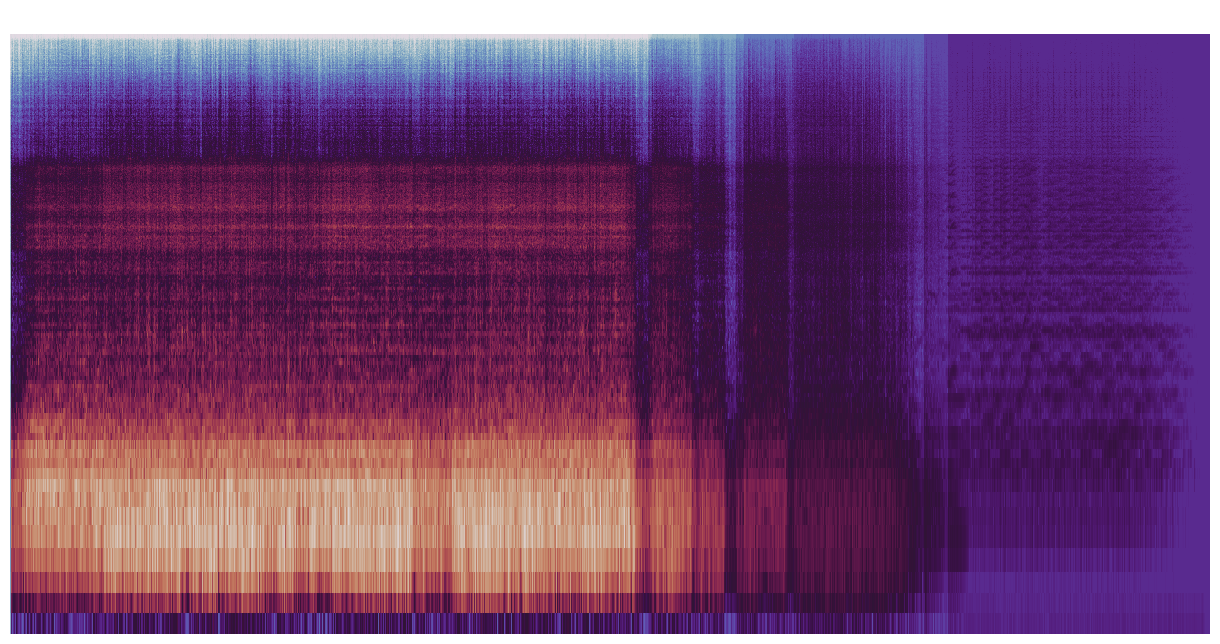

In [37]:
# Testing our function with the Symbolic album

files_symbolic = list_audio_files(SYMBOLIC)

plot_album_mean_spectrogram(files_symbolic, "Symbolic (1995)", kind='stft')



In [49]:
files_spiritual = list_audio_files(SPIRITUAL_HEALING)

plot_album_mean_spectrogram(files_spiritual, "Spiritual Healing (1990)", kind='mel')

The following songs were found in this album:
 - 01-Living Monstrosity.flac
 - 02-Altering The Future.flac
 - 03-Defensive Personalities.flac
 - 04-Within The Mind.flac
 - 05-Spiritual Healing.flac
 - 06-Low Life.flac
 - 07-Genetic Reconstruction.flac
 - 08-Killing Spree.flac
Processing 8 songs in th album: Spiritual Healing (1990)...
La longitud máxima detectada es de 40189 fotogramas. Ajustando...


TypeError: object of type 'int' has no len()